---

# 2025 World Happiness Score  

## Project Focus  
This project centers on analyzing the **World Happiness Score** and the key features that influence **Healthy Life Expectancy**, with the aim of understanding how socio-economic factors contribute to overall well-being.  

## Understanding the World Happiness Score  
The World Happiness Score (often referred to as the *Ladder score*) reflects how individuals across countries perceive their quality of life. It is shaped by several variables, including:  

- Year 
- Rank
- Country name  
- Life evaluation (3-year average) 
- Lower whisker / Upper whisker
- Explained by log GDP per capita 
- Explained by social support
- Explained by healthy life expectancy 
- Explained by freedom to make life choices 
- Explained by generosity  
- Explained by perceptions of corruption 
- Dystopia residual 

Among these, **Healthy Life Expectancy** is a critical component, as it directly reflects physical well-being and longevity.  

## Research Objectives  
This project explores the **relationship between happiness and health** by:  

- Identifying which factors most strongly influence **Healthy Life Expectancy**  
- Examining how these factors contribute to the **overall happiness score**  
- Analyzing correlations and patterns across countries and regions  

## Methodology  
To achieve these objectives, the project leverages:  

- **Correlation analysis**  
- **Data visualization**  
- **Predictive modeling**  

These techniques help uncover meaningful insights into how economic, social, and health-related variables interact.  

## Key Insights  
Ultimately, this analysis provides a deeper understanding of:  

- Why some countries achieve **higher levels of happiness and health**  
- How indicators like **GDP** and **social support** impact **life expectancy**  
- The broader connection between **quality of life and national well-being**  

---

The data frame include the following features:

## Load Libraries

In [75]:
import warnings
warnings.simplefilter('ignore')

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Load the dataset from the storage

In [77]:
#pip install openpyxl

### Load the dataset for PCA 

In [78]:
data = pd.read_excel("WHR26_Data_Figure_2.1.xlsx")
data.head(5)

,Year,Rank,Country name,Life evaluation (3-year average),Lower whisker,Upper whisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,2025,1,Finland,7.764,7.690,7.837,1.915,1.638,0.939,1.105,0.093,0.491,1.582
1,2025,2,Iceland,7.540,7.449,7.630,1.971,1.720,0.996,1.105,0.187,0.187,1.373
2,2025,3,Denmark,7.539,7.446,7.631,1.986,1.633,0.930,1.081,0.125,0.474,1.310
3,2025,4,Costa Rica,7.439,7.356,7.522,1.697,1.483,0.739,1.101,0.059,0.122,2.236
4,2025,5,Sweden,7.255,7.172,7.337,1.950,1.570,1.027,1.070,0.149,0.447,1.041


In [79]:
#clean the columns
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[\s:]+", "_", regex=True)
    .str.replace(r"[^a-z0-9_]", "", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

print(data.columns.tolist())

['year', 'rank', 'country_name', 'life_evaluation_3year_average', 'lower_whisker', 'upper_whisker', 'explained_by_log_gdp_per_capita', 'explained_by_social_support', 'explained_by_healthy_life_expectancy', 'explained_by_freedom_to_make_life_choices', 'explained_by_generosity', 'explained_by_perceptions_of_corruption', 'dystopia_residual']


In [80]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2116 entries, 0 to 2115
Data columns (total 13 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   year                                       2116 non-null   int64  
 1   rank                                       2116 non-null   int64  
 2   country_name                               2116 non-null   str    
 3   life_evaluation_3year_average              2116 non-null   float64
 4   lower_whisker                              1022 non-null   float64
 5   upper_whisker                              1022 non-null   float64
 6   explained_by_log_gdp_per_capita            1019 non-null   float64
 7   explained_by_social_support                1019 non-null   float64
 8   explained_by_healthy_life_expectancy       1016 non-null   float64
 9   explained_by_freedom_to_make_life_choices  1017 non-null   float64
 10  explained_by_generosity            

In [81]:
print(f"Total duplicates value in the dataframe",data.duplicated().sum())

Total duplicates value in the dataframe 0


There's no duplicate value in the dataset, well so we can go streight to data exploratory analysis for fearther exploratory


Most of the features in the dataset are numerical, meaning they consist of quantitative values that can be directly used for statistical analysis and machine learning models. These numerical variables likely represent measurable indicators such as scores, rates, or indices, making them suitable for operations like correlation analysis, normalization, and regression.

In contrast, only two columns—**Country name** and **Regional indicator**—are categorical features. These variables represent qualitative data rather than numerical values. The **Country name** column serves primarily as an identifier for each observation and typically does not contribute directly to predictive modeling unless transformed or encoded. The **Regional indicator** groups countries into broader geographic or socio-economic regions, which can provide useful contextual information but must be converted into a numerical format (e.g., one-hot encoding or label encoding) before being used in most machine learning algorithms.



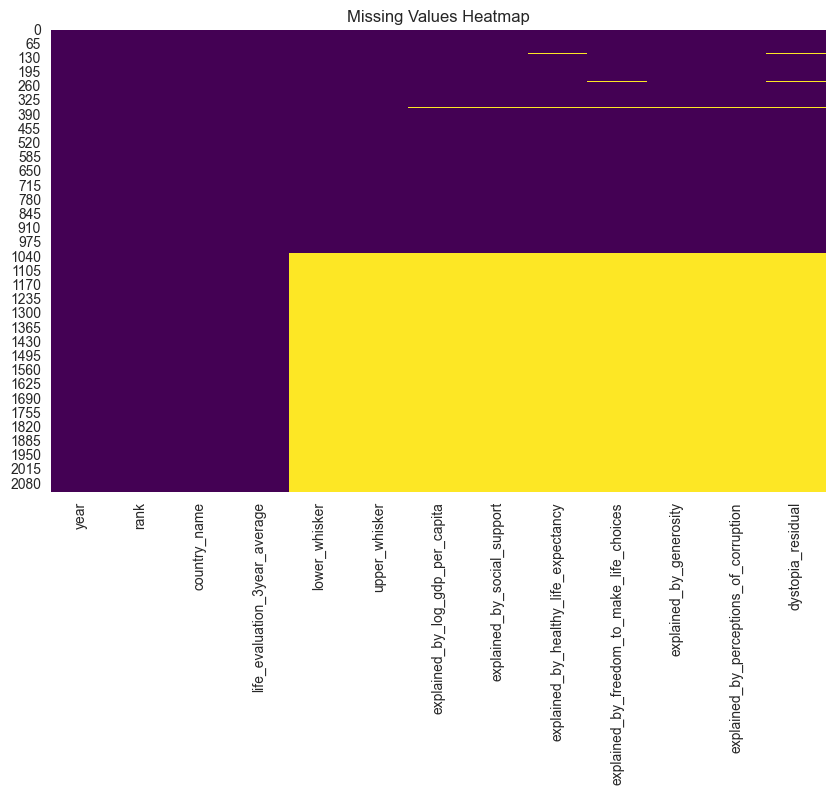

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

## Project Structure

We are going to divide this project into **two main parts**. Each part will focus on a different aspect of the dataset and analysis.

### Part 1: Exploratory Data Analysis

The first part of the project will focus on **analysing four key features** from the dataset:

* `year`
* `rank`
* `country_name`
* `life_evaluation_3year_average`

The objective of this section is to understand the **overall distribution and trends in life evaluation across different countries and years**.

We will investigate questions such as:

* How has the life evaluation score changed over the years?
* Which countries consistently achieve the highest and lowest rankings?
* Is there a relationship between a country's `rank` and its `life_evaluation_3year_average`?
* How does life evaluation vary between countries?
* Are there noticeable trends or changes in country rankings over time?
* Which countries show significant improvements or declines in their life evaluation scores?

This stage will primarily involve **data exploration and visualization**. We can use charts such as line charts, bar charts, scatter plots, and ranking visualizations to identify patterns and trends within the data.

The goal of Part 1 is to develop a clear understanding of the dataset **before applying any machine-learning techniques**.

---

### Part 2: K-Means Clustering

The second part of the project will focus on applying the **K-Means Clustering** machine-learning algorithm.

K-Means is an **unsupervised learning method** that groups observations with similar characteristics into clusters. Instead of analysing countries individually, we will attempt to identify **groups of countries that share similar patterns**.

For this analysis, we can use relevant numerical features from the dataset to determine similarities between countries. Before applying K-Means, the data will need to be prepared appropriately, including:

1. Selecting the features to be used for clustering.
2. Handling missing or inconsistent values.
3. Removing features that should not influence the clustering where appropriate.
4. Scaling/standardising the numerical variables.
5. Determining an appropriate number of clusters (`K`).
6. Applying the K-Means algorithm.
7. Analysing and interpreting the resulting clusters.

We can use methods such as the **Elbow Method** and **Silhouette Score** to help determine a suitable value for `K`.

After creating the clusters, we will investigate what each group represents. For example, the analysis may reveal groups of countries with:

* High life evaluation and high rankings.
* Moderate life evaluation and middle rankings.
* Lower life evaluation and lower rankings.
* Similar life evaluation patterns across different years.

The important point is that the clusters will **not be predefined**. K-Means will identify the groups based on similarities within the selected features, and we will then interpret what those groups mean.

---

## Overall Objective

By dividing the project into these two parts, we move from **understanding the data** to **discovering hidden patterns within the data**.

**Part 1 → Analysis & Understanding**

We first explore `year`, `rank`, `country_name`, and `life_evaluation_3year_average` to understand trends, rankings, and differences between countries.

**Part 2 → Machine Learning & Pattern Discovery**

We then apply **K-Means Clustering** to identify groups of countries with similar characteristics and investigate what distinguishes one cluster from another.

This two-stage approach allows us to build a strong foundation with exploratory analysis before moving into machine learning and ensures that the clustering results can be interpreted in the context of the patterns discovered during Part 1.


In [83]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2116 entries, 0 to 2115
Data columns (total 13 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   year                                       2116 non-null   int64  
 1   rank                                       2116 non-null   int64  
 2   country_name                               2116 non-null   str    
 3   life_evaluation_3year_average              2116 non-null   float64
 4   lower_whisker                              1022 non-null   float64
 5   upper_whisker                              1022 non-null   float64
 6   explained_by_log_gdp_per_capita            1019 non-null   float64
 7   explained_by_social_support                1019 non-null   float64
 8   explained_by_healthy_life_expectancy       1016 non-null   float64
 9   explained_by_freedom_to_make_life_choices  1017 non-null   float64
 10  explained_by_generosity            

### We have two types of data format in the data frame

**2 Calegorical**

Regional column and Country name

**10 Numerical**

And the remains columns are numericals   

In [84]:
duplicates = data.duplicated().sum()

data['year'] = data['year'].astype(str)

print(f"The total number of duplicates values in dataframe are {duplicates}")

print("The total size remain:", len(data))

The total number of duplicates values in dataframe are 0
The total size remain: 2116


We don't have duplicate value in the dataset, the dataset is clean after removing all the null value.

## Exoloratory Data Analaysis(EDA)

#### Discriptive Analysis

In [85]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rank,2116.0,76.190926,43.845101,1.000,38.000000,76.000000,114.000000,158.000000
life_evaluation_3year_average,2116.0,5.465655,1.123870,1.364,4.604750,5.480000,6.321250,7.856000
lower_whisker,1022.0,5.436091,1.140959,1.301,4.619707,5.592631,6.290110,7.780000
upper_whisker,1022.0,5.664733,1.107424,1.427,4.867750,5.812000,6.486500,7.904000
explained_by_log_gdp_per_capita,1019.0,1.265670,0.463823,0.000,0.944000,1.304000,1.636000,2.209000
explained_by_social_support,1019.0,1.096746,0.357642,0.000,0.865000,1.140119,1.382000,1.840000
explained_by_healthy_life_expectancy,1016.0,0.553435,0.229980,0.000,0.389750,0.560500,0.712325,1.238000
explained_by_freedom_to_make_life_choices,1017.0,0.609465,0.212070,0.000,0.471000,0.602000,0.735000,1.147000
explained_by_generosity,1019.0,0.147343,0.084335,0.000,0.088000,0.134000,0.195477,0.569814
explained_by_perceptions_of_corruption,1018.0,0.144911,0.118803,0.000,0.063156,0.113000,0.181330,0.587000


Plot distribution of the all numerical column with histoplot method techniques

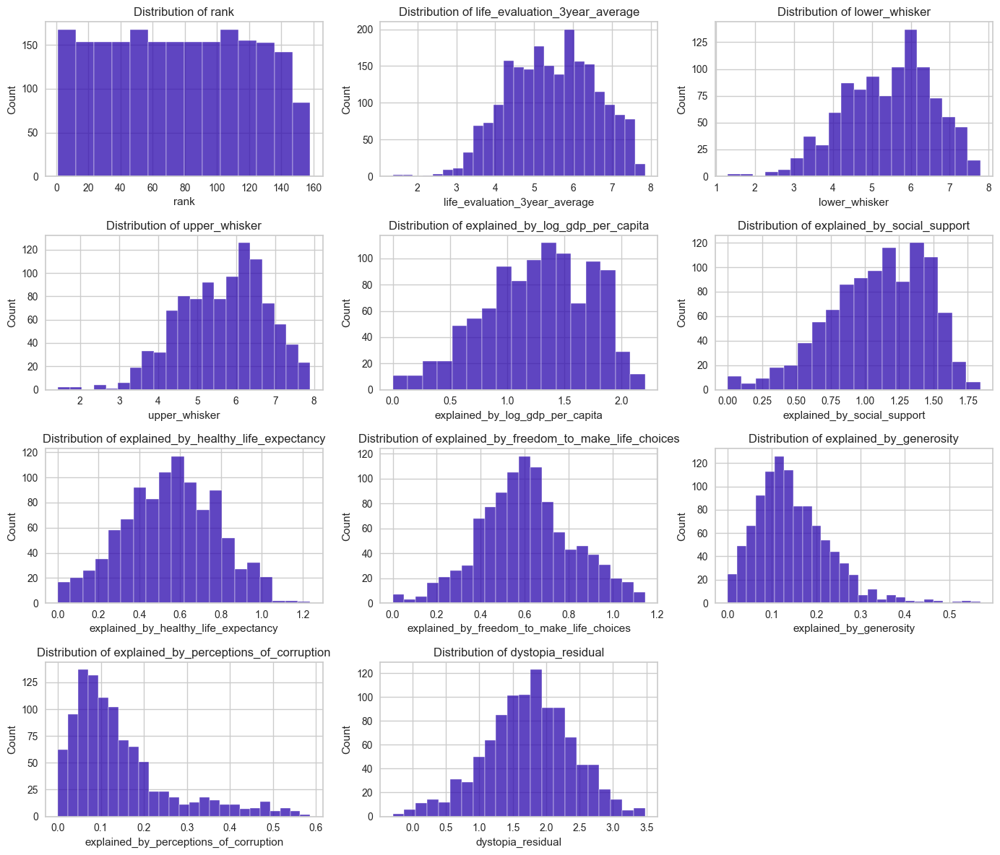

In [86]:
numerical_features = data.select_dtypes(include='number').columns # to get numberic features

#Plot histplot of all numerical columns
sns.set_style("whitegrid")

plt.figure(figsize=(14,12))

# Loop through numerical features
for i, column in enumerate(numerical_features, start=1):  # Use enumerate to get the index
    plt.subplot(4, 3, i)  # Adjust the number of rows and columns as needed
    sns.histplot(data[column], color="#2A06AD")
    plt.xlabel(column)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

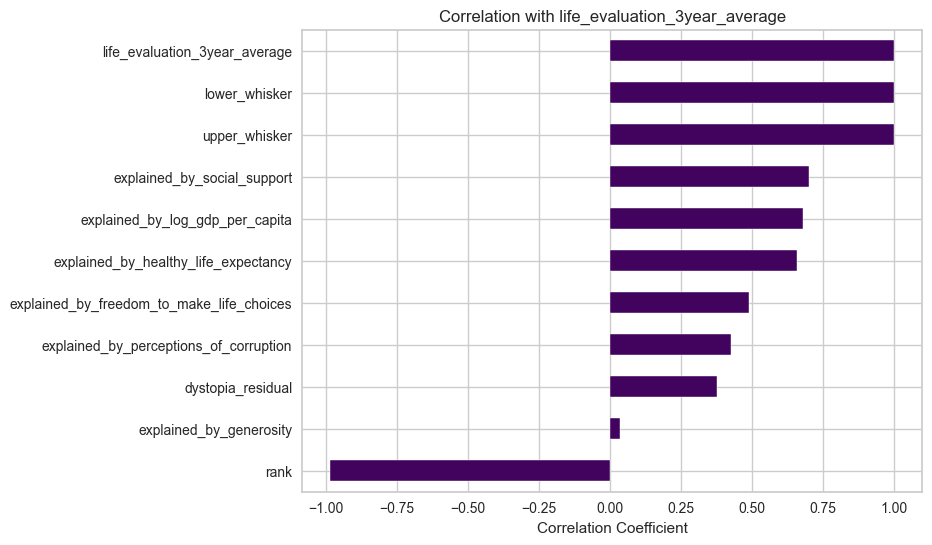

In [87]:
corr_with_target = data[numerical_features].corrwith(data['life_evaluation_3year_average']).sort_values()
plt.figure(figsize=(8, 6))
corr_with_target.plot(kind='barh', color="#42035F")
plt.title('Correlation with life_evaluation_3year_average')
plt.xlabel('Correlation Coefficient')
plt.show()

### Let Compare Spearman and Peason Correlation methods Simple Intuition

- Pearson → “Do these variables move in a straight line together?”
- Spearman → “Do these variables move in the same direction overall?”

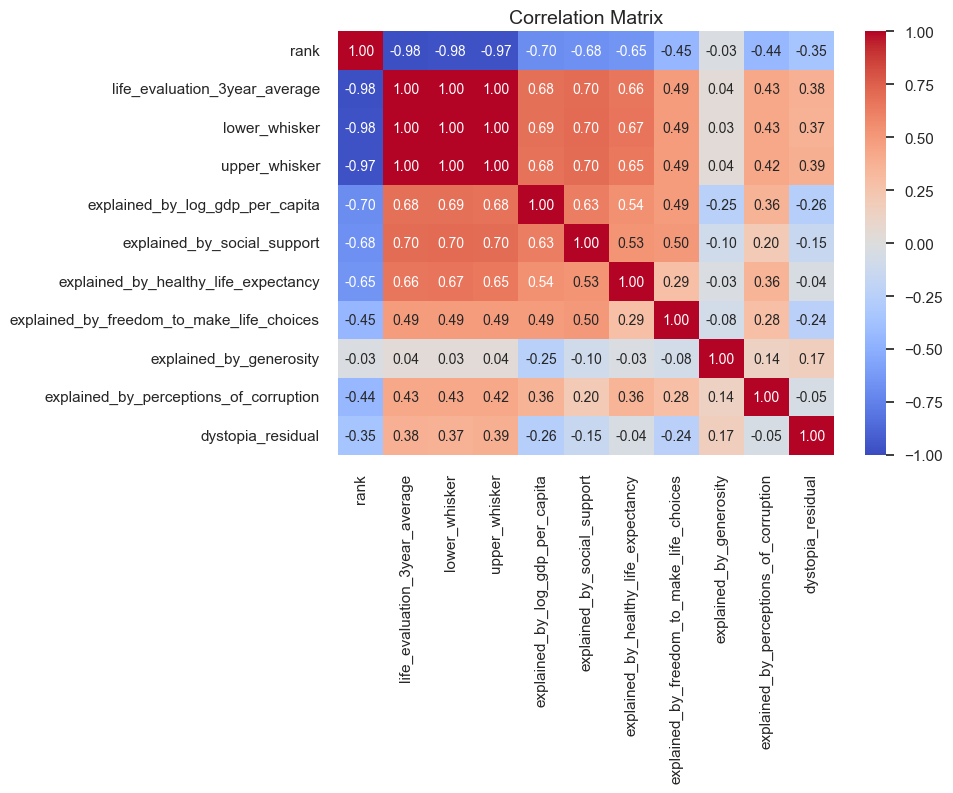

In [88]:

# Set style for better visuals
sns.set(style="white")

# Select numerical columns as a DataFrame
numerical_features = data.select_dtypes(include="number")
corr_matrix = numerical_features.corr()

# Plot heatmap
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", annot_kws={"size": 10},
    cmap="coolwarm", vmin=-1, vmax=1
)

plt.title("Correlation Matrix", fontsize=14)
plt.show()

### Pairplot Viz

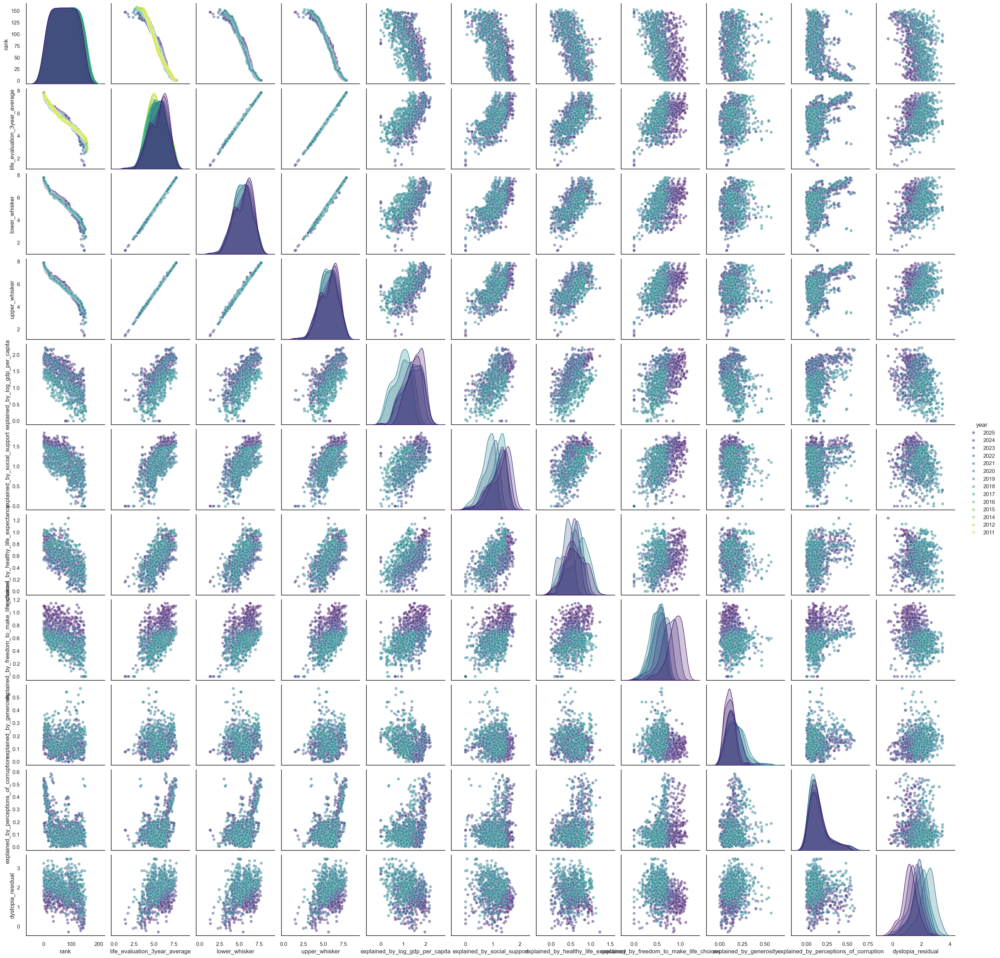

In [89]:
sns.pairplot(data=data, vars=numerical_features.columns, kind='scatter', diag_kind='kde', plot_kws={'alpha':0.5}, hue='year', palette='viridis')

## We'll filter the above column for the above analysis

In [90]:
features = [
    'year',
    'rank',
    'country_name',
    'life_evaluation_3year_average'
]

df = data[features].copy()

In [91]:
df.isna().sum()

year                             0
rank                             0
country_name                     0
life_evaluation_3year_average    0
dtype: int64

In [92]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage

year                             0.0
rank                             0.0
country_name                     0.0
life_evaluation_3year_average    0.0
dtype: float64

In [93]:
df.duplicated(
    subset=['year', 'country_name']
).sum()

np.int64(0)

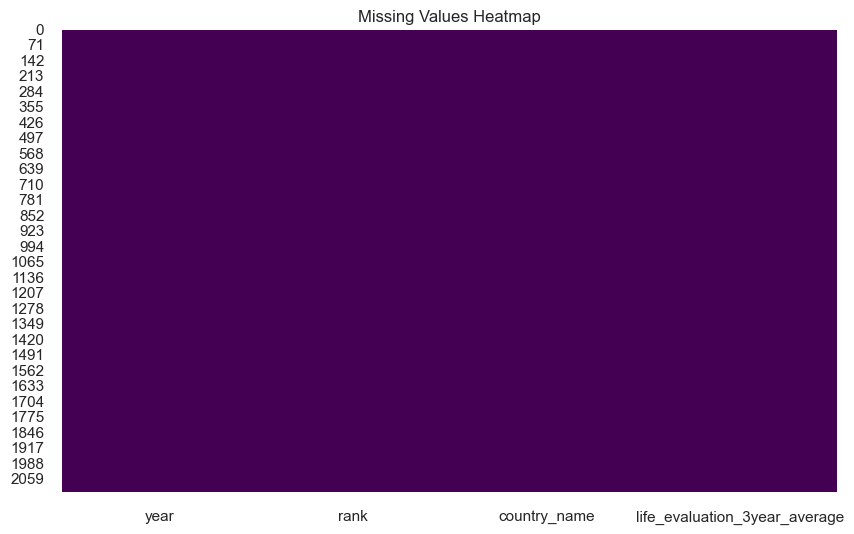

In [94]:
#forward fillna method we'll be use in this project
df = df.ffill()

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

Number of countries over time

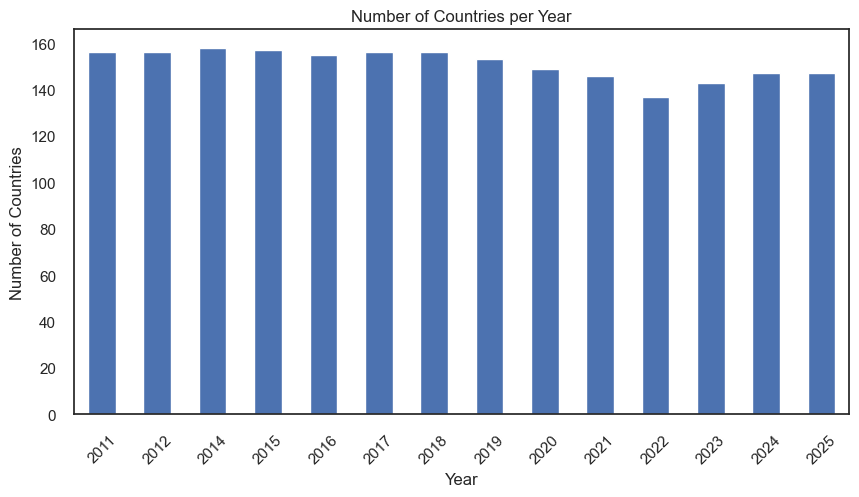

In [95]:
plt.figure(figsize=(10, 5))

df['year'].value_counts().sort_index().plot(kind='bar')

plt.title('Number of Countries per Year')
plt.xlabel('Year')
plt.ylabel('Number of Countries')
plt.xticks(rotation=45)
plt.show()

Distribution of Life Evaluation

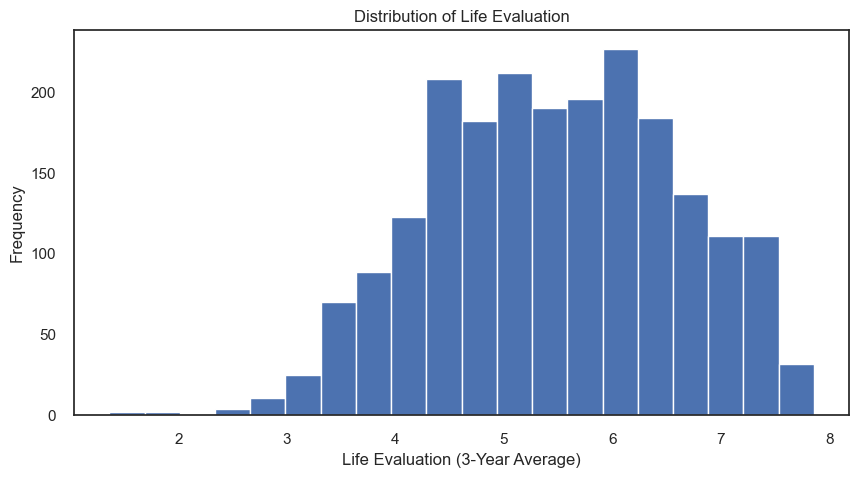

In [96]:
plt.figure(figsize=(10, 5))

plt.hist(
    df['life_evaluation_3year_average'],
    bins=20
)

plt.title('Distribution of Life Evaluation')
plt.xlabel('Life Evaluation (3-Year Average)')
plt.ylabel('Frequency')

plt.show()

Data transformation
We'll add two more column Alone time and Going outside type


In [97]:

def rank_categories(x):
    if x <= 11:
        return "10_top"
    elif x <= 40:
        return "top_40"
    else:
        return "above_top40"

data['rank_categories'] = data['rank'].apply(rank_categories)

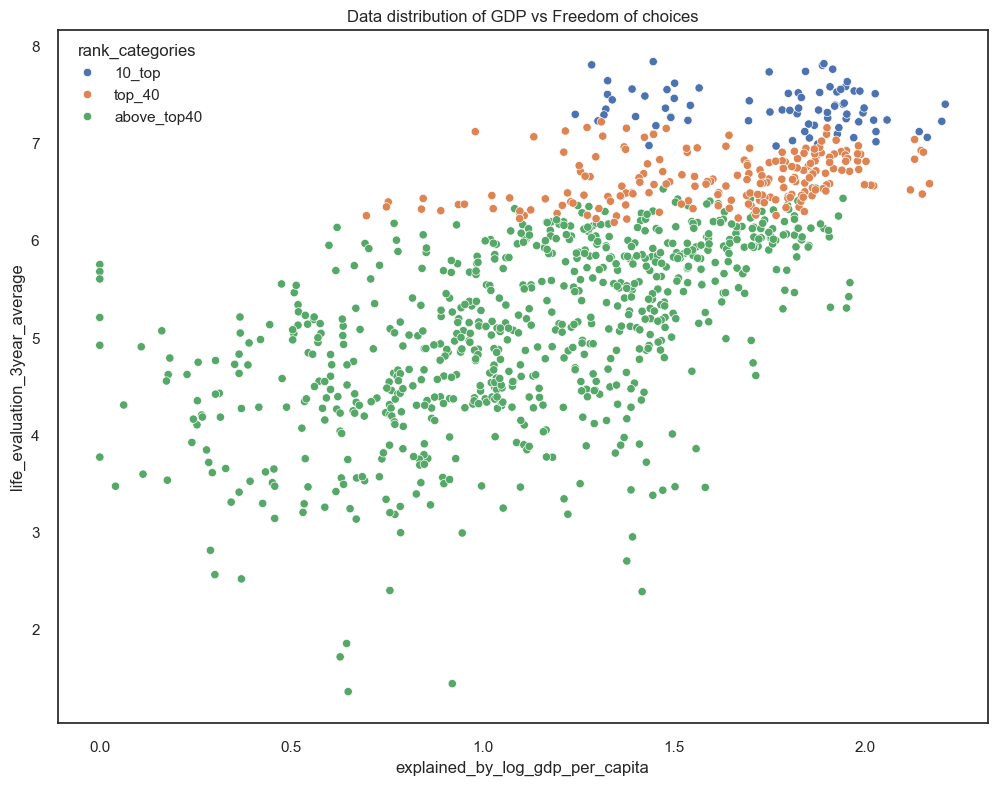

In [98]:
plt.figure(figsize=(12,9))
sns.scatterplot(data=data, x='explained_by_log_gdp_per_capita', y='life_evaluation_3year_average', hue="rank_categories")
plt.title("Data distribution of GDP vs Freedom of choices")
plt.show()

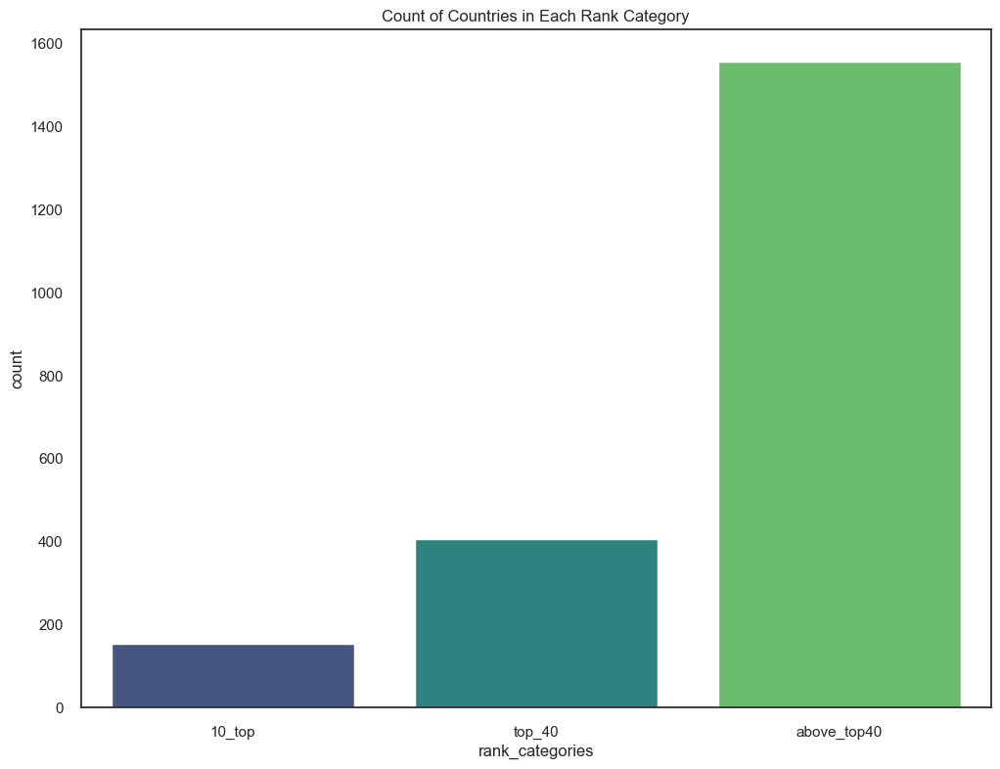

In [99]:
plt.figure(figsize=(12,9))
sns.countplot(data=data, x='rank_categories', palette="viridis")
plt.title("Count of Countries in Each Rank Category")   
plt.show()

Now things get more interesting.

We're going to investigate relationships between our variables.

## Rank vs Life Evaluation

This should be one of our key analyses.

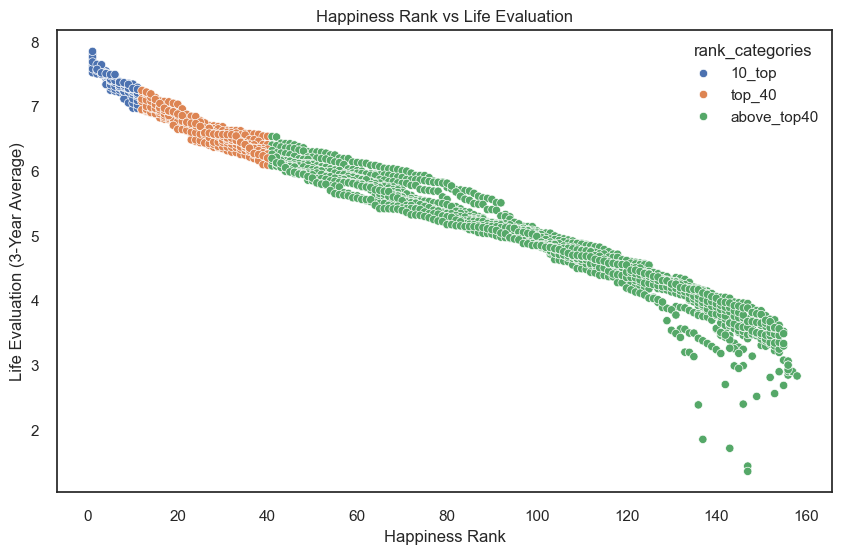

In [100]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x='rank',
    y='life_evaluation_3year_average',
    hue="rank_categories"
)

plt.title('Happiness Rank vs Life Evaluation')
plt.xlabel('Happiness Rank')
plt.ylabel('Life Evaluation (3-Year Average)')

plt.show()

We can also calculate Spearman correlation because rank is an ordinal/ranking variable:

In [101]:
df[
    ['rank', 'life_evaluation_3year_average']
].corr(
    method='spearman'
)

,rank,life_evaluation_3year_average
rank,1.000000,-0.993181
life_evaluation_3year_average,-0.993181,1.000000


## Happiness over time

Now let's answer:

Has global life evaluation changed over time?

Calculate the yearly average:

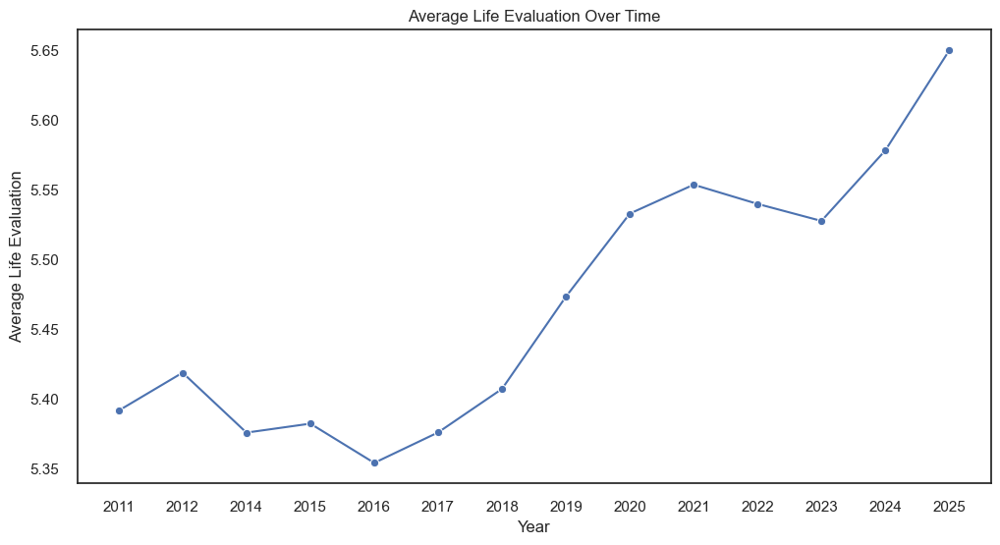

In [102]:
yearly_happiness = (
    df
    .groupby('year')['life_evaluation_3year_average']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_happiness,
    x='year',
    y='life_evaluation_3year_average',
    marker='o'
)

plt.title('Average Life Evaluation Over Time')
plt.xlabel('Year')
plt.ylabel('Average Life Evaluation')

plt.show()

## Top countries

We can investigate the countries with the highest average life evaluation.


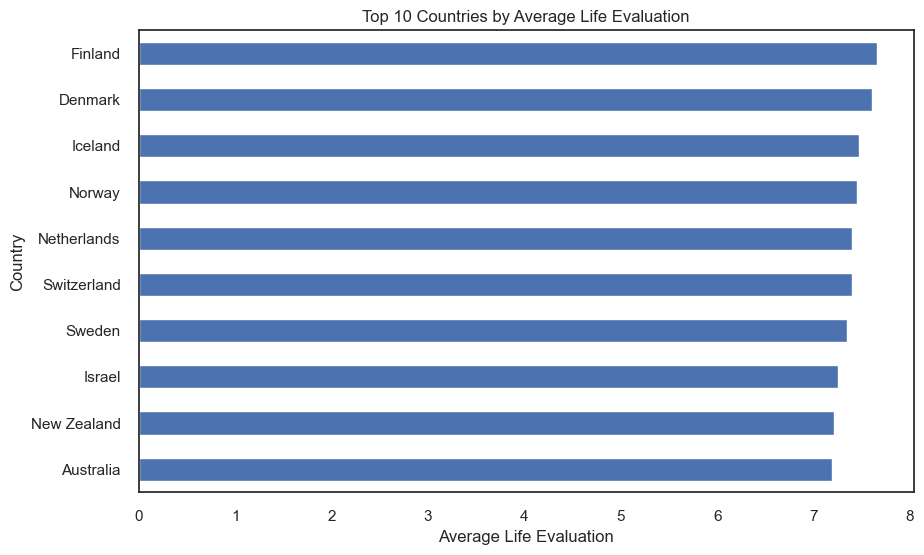

In [103]:
top_countries = (
    df.groupby('country_name')['life_evaluation_3year_average']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_countries

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Average Life Evaluation')
plt.xlabel('Average Life Evaluation')
plt.ylabel('Country')

plt.show()

This is much more informative than simply taking the top 10 rows because a country may appear multiple times across different years.

## Bottom countries

We should also look at the other side:


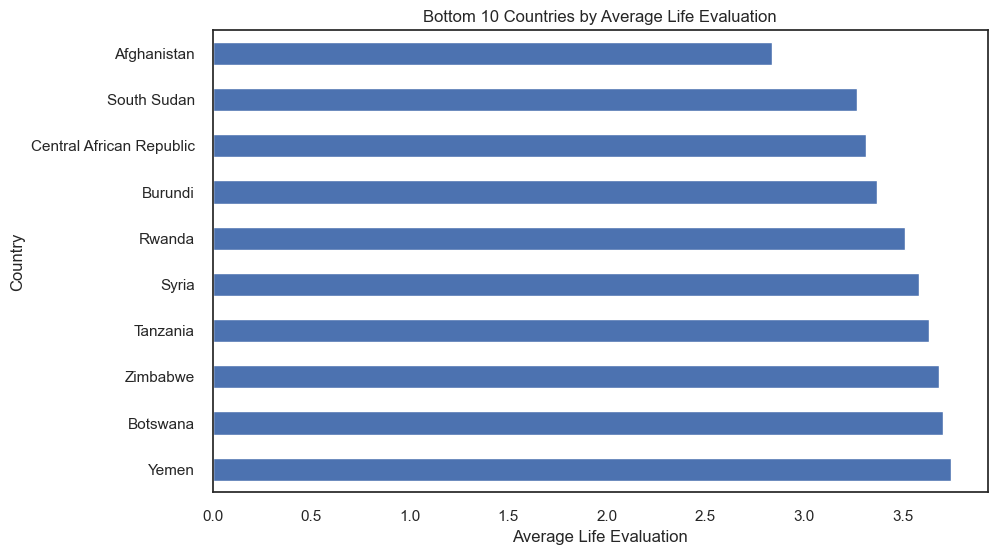

In [104]:
bottom_countries = (
    df.groupby('country_name')['life_evaluation_3year_average']
    .mean()
    .sort_values()
    .head(10)
)

bottom_countries

plt.figure(figsize=(10, 6))

bottom_countries.sort_values(ascending=False).plot(kind='barh')

plt.title('Bottom 10 Countries by Average Life Evaluation')
plt.xlabel('Average Life Evaluation')
plt.ylabel('Country')

plt.show()

## Country trends over time

This is where our EDA becomes more sophisticated.

Instead of asking:

Which countries are happiest?

we can ask:

Which countries are improving or declining over time?

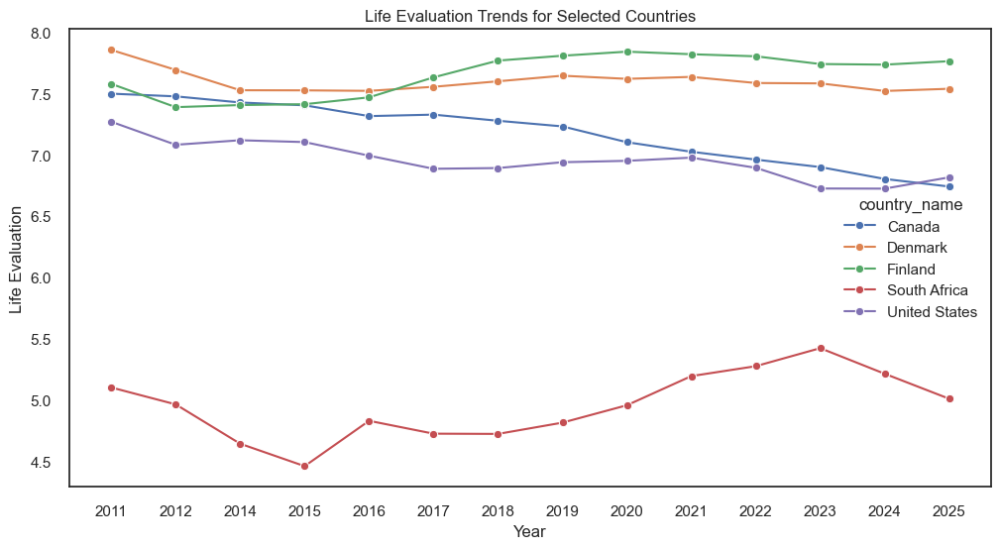

In [105]:
country_year = (
    df.groupby(['year', 'country_name'])
    ['life_evaluation_3year_average']
    .mean()
    .reset_index()
)

selected_countries = [
    'Finland',
    'Denmark',
    'Canada',
    'South Africa',
    'United States'
]

trend = country_year[
    country_year['country_name'].isin(selected_countries)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=trend,
    x='year',
    y='life_evaluation_3year_average',
    hue='country_name',
    marker='o'
)

plt.title('Life Evaluation Trends for Selected Countries')
plt.xlabel('Year')
plt.ylabel('Life Evaluation')
plt.show()

## Rank changes

We can perform the same analysis with rank.

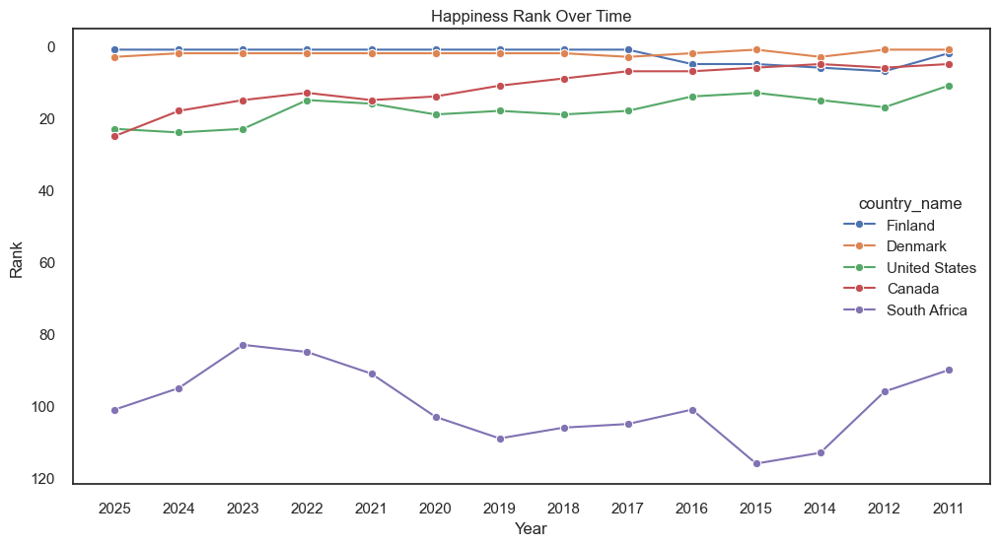

In [106]:
rank_trend = df[
    df['country_name'].isin(selected_countries)
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=rank_trend,
    x=rank_trend.sort_values("year")["year"],
    y=rank_trend.sort_values("year")["rank"],
    hue='country_name',
    marker='o'
)

plt.gca().invert_yaxis()

plt.title('Happiness Rank Over Time')
plt.xlabel('Year')
plt.ylabel('Rank')

plt.show()

## Southern african countries Happiness Ranks over time

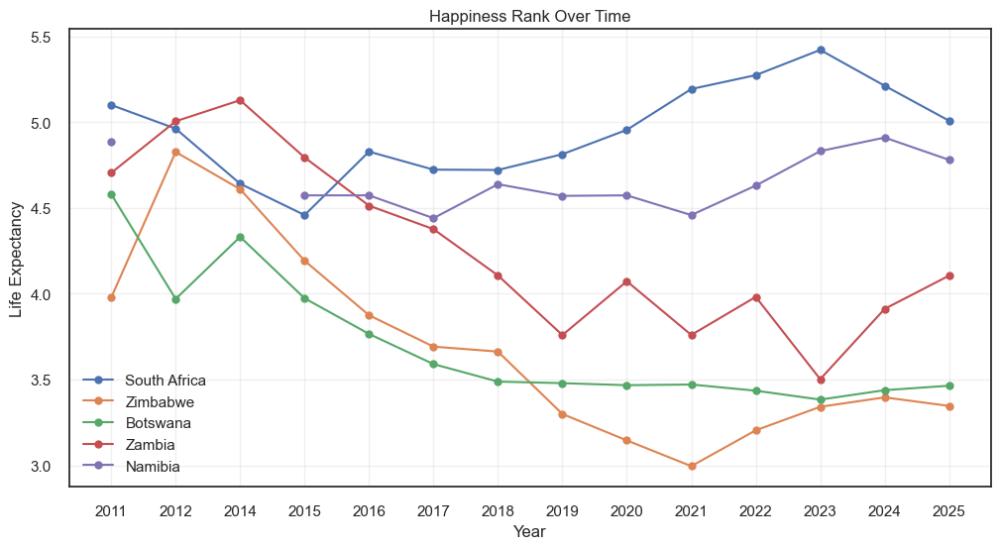

In [107]:
life_exp_pivot = df.pivot_table(
    index="country_name",
    columns="year",
    values="life_evaluation_3year_average",
    aggfunc="mean"
)
# Plot life expectetion of south africa Overtime

# Clean up country names (remove accidental spaces)
country = ["South Africa", "Zimbabwe", "Botswana", "Zambia","Namibia"]

plt.figure(figsize=(12, 6))

# Loop through each country and plot its life expectancy
for c in country:
    plt.plot(
        life_exp_pivot.columns,          # years
        life_exp_pivot.loc[c],           # values for that country
        marker="o",
        label=c                          # add legend label
    )

plt.title('Happiness Rank Over Time')
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.grid(True, alpha=0.3)
plt.legend()  # show legend for countries
plt.show()


## Plot life expectetion per country Overtime

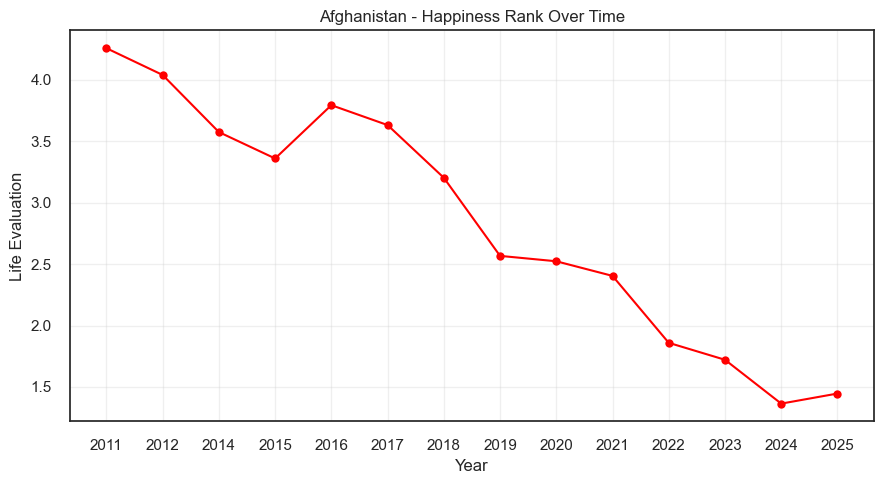

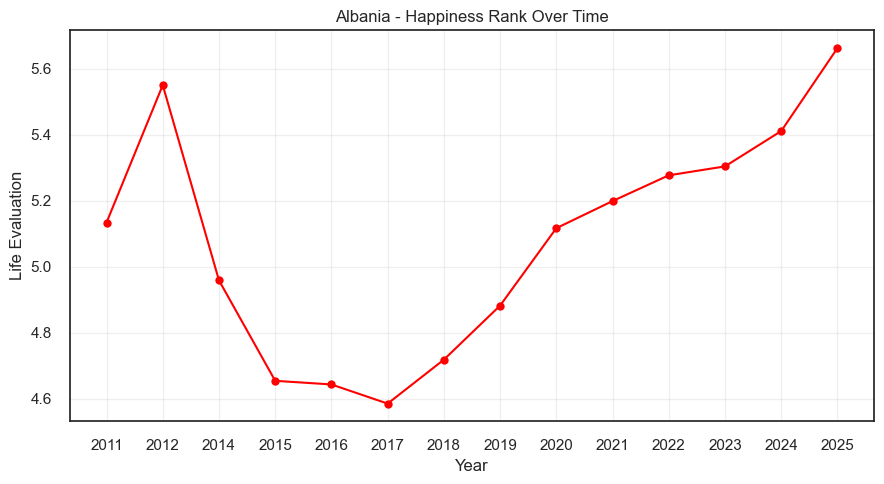

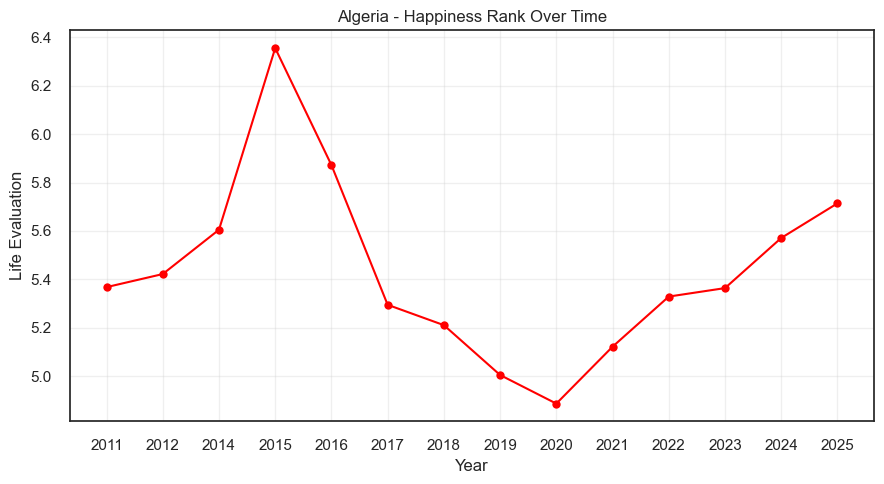

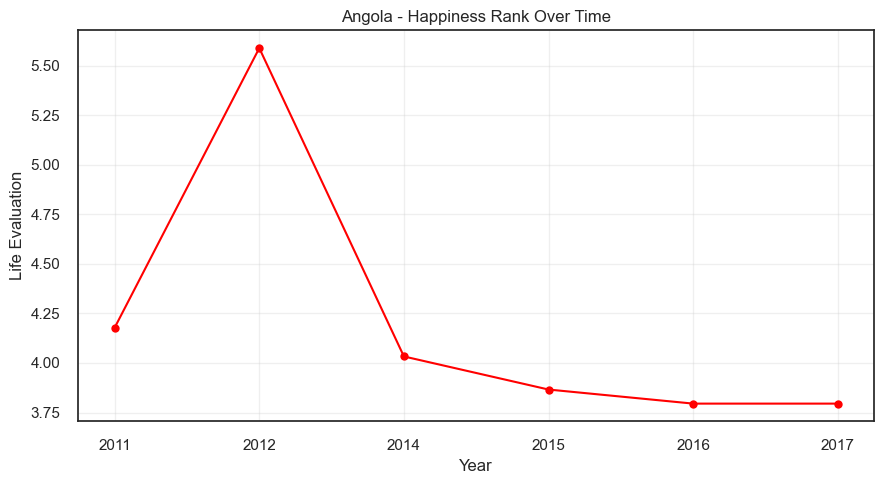

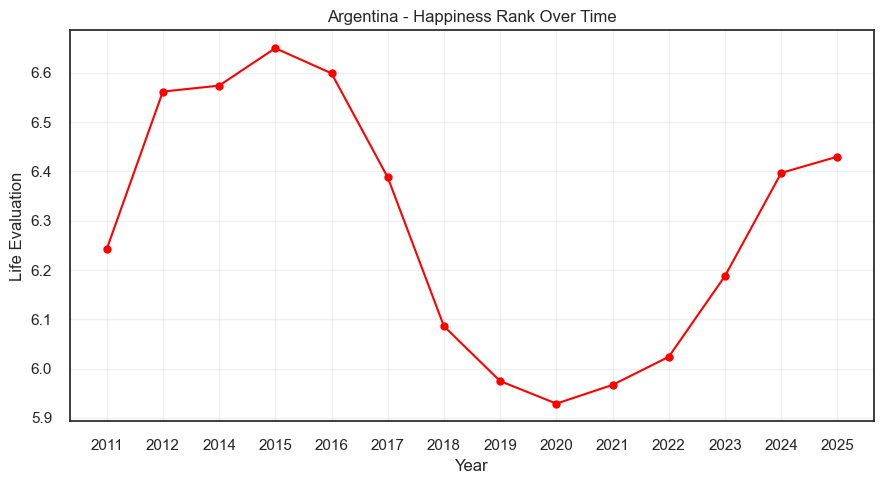

...

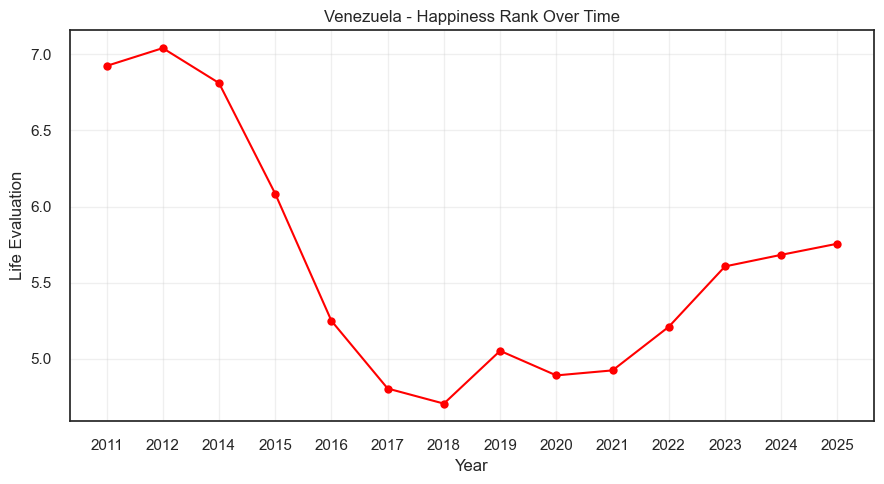

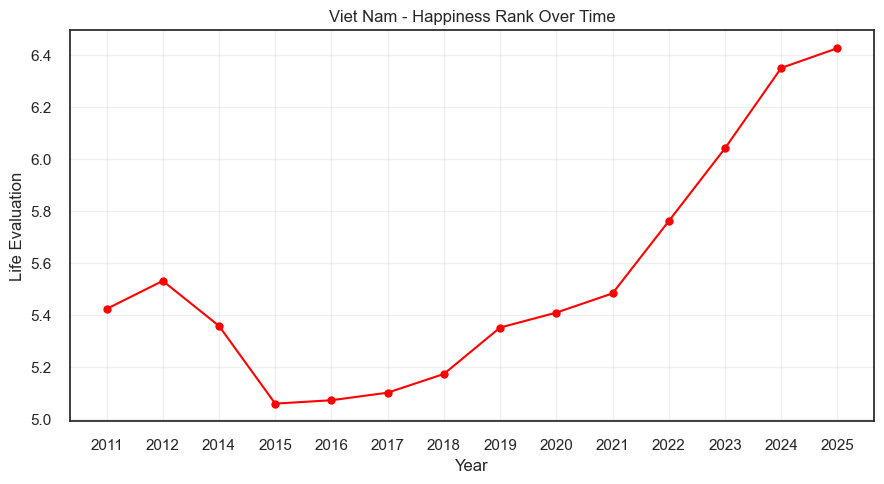

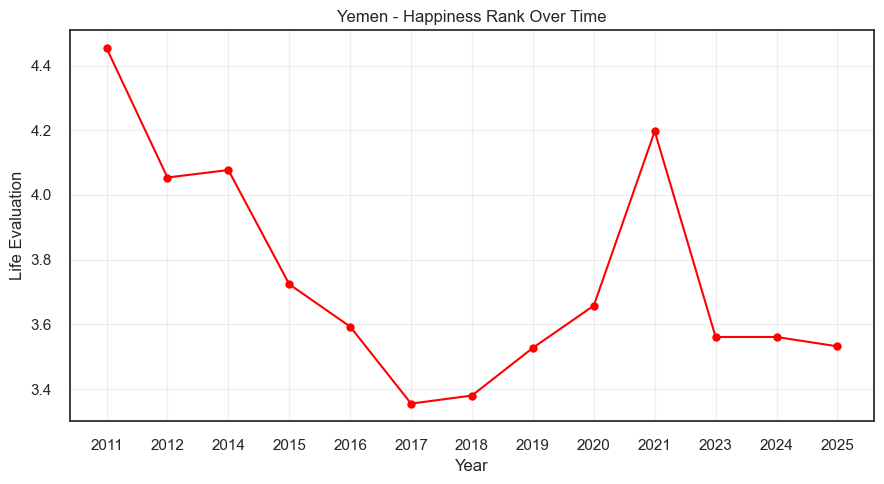

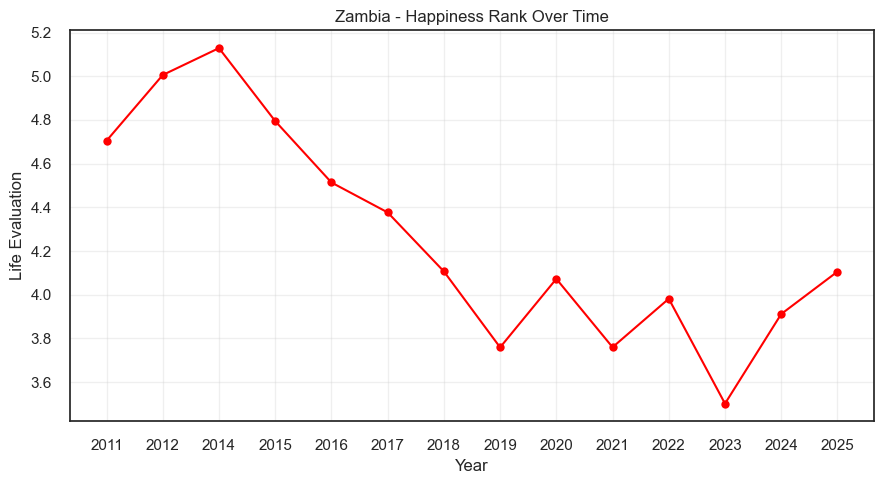

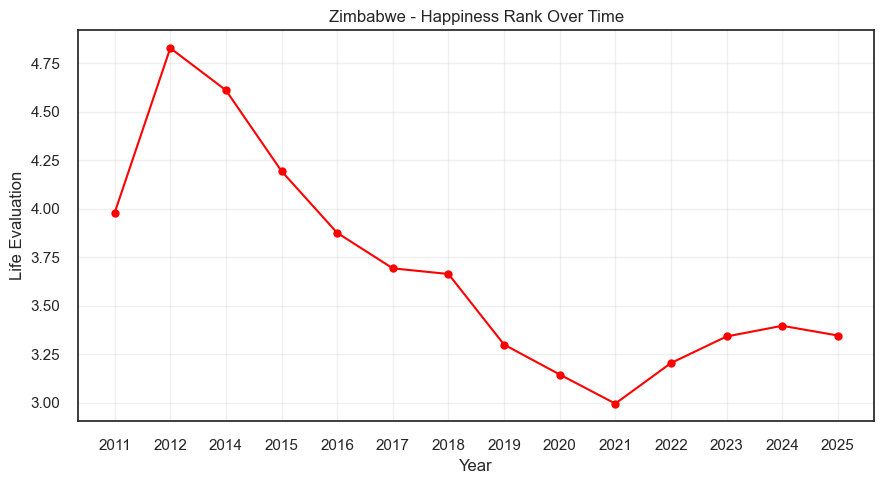

country_name
Afghanistan    (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Albania        (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Algeria        (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Angola         (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Argentina      (Figure(900x500), [Line2D(_child0)], Text(0.5,...
                                     ...                        
Venezuela      (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Viet Nam       (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Yemen          (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Zambia         (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Zimbabwe       (Figure(900x500), [Line2D(_child0)], Text(0.5,...
Length: 168, dtype: object

In [108]:
import matplotlib.pyplot as plt

df.groupby("country_name").apply(
    lambda country: (
        plt.figure(figsize=(9, 5)),
        plt.plot(
            country.sort_values("year")["year"],
            country.sort_values("year")["life_evaluation_3year_average"],
            marker="o", color='red'
        ),
        plt.title(f"{country.name} - Happiness Rank Over Time"),
        plt.xlabel("Year"),
        plt.ylabel("Life Evaluation"),
        plt.grid(True, alpha=0.3),
        plt.tight_layout(),
        plt.show()
    )
)

## A useful EDA summary table

Before moving to K-Means, I'd create a country-level summary:

In [109]:
country_summary = (
    df
    .groupby('country_name')
    .agg(
        average_rank=('rank', 'mean'),
        average_life_evaluation=(
            'life_evaluation_3year_average',
            'mean'
        ),
        rank_std=('rank', 'std'),
        life_evaluation_std=(
            'life_evaluation_3year_average',
            'std'
        ),
        years_observed=('year', 'nunique')
    )
    .reset_index()
)

country_summary.head()

,country_name,average_rank,average_life_evaluation,rank_std,life_evaluation_std,years_observed
0,Afghanistan,145.928571,2.838993,6.719252,0.985744,14
1,Albania,93.928571,5.078550,13.589953,0.348097,14
2,Algeria,79.500000,5.437150,18.379545,0.375842,14
3,Angola,126.000000,4.209333,31.949961,0.692355,6
4,Argentina,41.357143,6.286479,11.926745,0.260081,14


In [110]:
country_summary.shape

(168, 6)

## K-Means Clustering Analysis

### Introduction
This markdown cell describes the analysis of K-Means clustering performed on a dataset using various distance metrics and dimensionality reduction techniques.

### 1. Define the clustering problem

Our objective becomes:

Identify groups of countries with similar happiness characteristics based on their happiness ranking, life evaluation, economic conditions, social support, health, freedom, generosity, corruption perceptions, and related indicators.

This is different from Part 1.

Part 1

We ask:

What does the World Happiness data tell us?

Part 2

We ask:

Which countries behave similarly according to their happiness characteristics?

For example, K-Means might discover groups resembling:

### Code Explanation
The provided code performs K-Means clustering on a dataset using the following steps:

> Importing Libraries:
 The code imports necessary libraries including NumPy for numerical operations, scikit-learn for K-Means clustering, pairwise distance calculations, and PCA for dimensionality reduction.

* Clustering with K-Means: The KMeans class from scikit-learn is initialized with 3 clusters and fitted to the dataset.

* Computing Distances: Euclidean, Manhattan, and Cosine distances between data points and cluster centers are computed using the euclidean_distances, manhattan_distances, and cosine_distances functions.

* Dimensionality Reduction: Principal Component Analysis (PCA) is used to reduce the dimensionality of the dataset.

Import python libraries

In [111]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from sklearn.decomposition import PCA


In [112]:
data = pd.read_excel("WHR26_Data_Figure_2.1.xlsx")

In [113]:
#clean the columns
data.columns = (
    data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[\s:]+", "_", regex=True)
    .str.replace(r"[^a-z0-9_]", "", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.strip("_")
)

print(data.columns.tolist())

['year', 'rank', 'country_name', 'life_evaluation_3year_average', 'lower_whisker', 'upper_whisker', 'explained_by_log_gdp_per_capita', 'explained_by_social_support', 'explained_by_healthy_life_expectancy', 'explained_by_freedom_to_make_life_choices', 'explained_by_generosity', 'explained_by_perceptions_of_corruption', 'dystopia_residual']


This time we'll remove the null value in the data frame

In [114]:
data.dropna(inplace=True)

In [115]:
print("The shape of the data frame after dropping the null values", data.shape) 

The shape of the data frame after dropping the null values (1013, 13)


In [116]:
data.duplicated().sum()

np.int64(0)

### Create country-level features

We can aggregate the numerical variables by country:

In [117]:
numeric_features = [
    'rank',
    'life_evaluation_3year_average',
    'lower_whisker',
    'upper_whisker',
    'explained_by_log_gdp_per_capita',
    'explained_by_social_support',
    'explained_by_healthy_life_expectancy',
    'explained_by_freedom_to_make_life_choices',
    'explained_by_generosity',
    'explained_by_perceptions_of_corruption',
    'dystopia_residual'
]

country_data = (
    data.groupby('country_name')[numeric_features]
    .mean()
    .reset_index()
)

This is much more appropriate for K-Means.

## What should we do with year?

Rather than simply taking the average year—which doesn't have much analytical meaning—we can create a useful temporal feature.

In [118]:
country_years = (
    data
    .groupby('country_name')['year']
    .agg(
        first_year='min',
        last_year='max',
        years_observed='nunique'
    )
    .reset_index()
)

country_data = country_data.merge(
    country_years,
    on='country_name',
    how='left'
)

In [119]:
clustering_features = [
    'rank',
    'life_evaluation_3year_average',
    'lower_whisker',
    'upper_whisker',
    'explained_by_log_gdp_per_capita',
    'explained_by_social_support',
    'explained_by_healthy_life_expectancy',
    'explained_by_freedom_to_make_life_choices',
    'explained_by_generosity',
    'explained_by_perceptions_of_corruption',
    'dystopia_residual'
]

X = country_data[clustering_features]

from sklearn.preprocessing import StandardScaler

#Without scaling, variables with larger numerical ranges can dominate the distance calculation. 
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

Determine the optimal number of clusters



In [120]:
# Perform clustering using the K-Means algorithm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from yellowbrick.cluster import KElbowVisualizer


In [121]:
inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)   

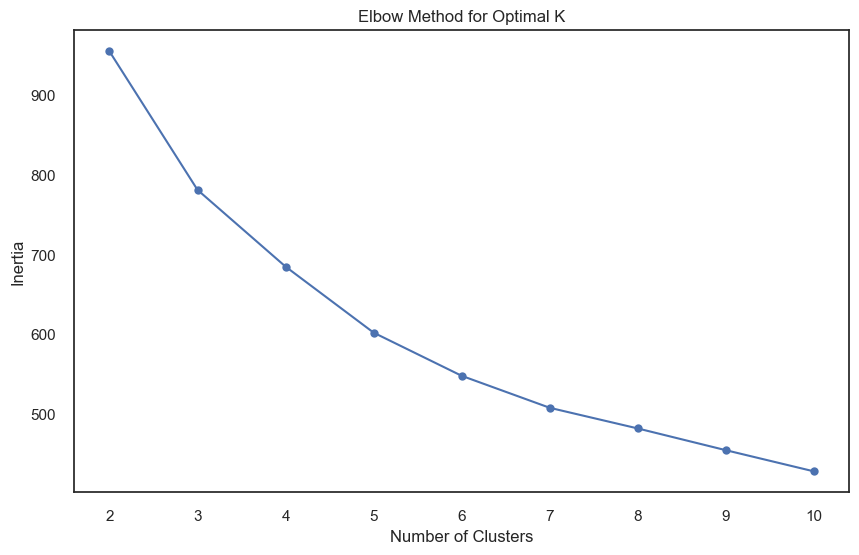

In [122]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.show()

## Silhouette Score

The elbow method shouldn't be our only criterion.

We'll also calculate the Silhouette Score:

In [123]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

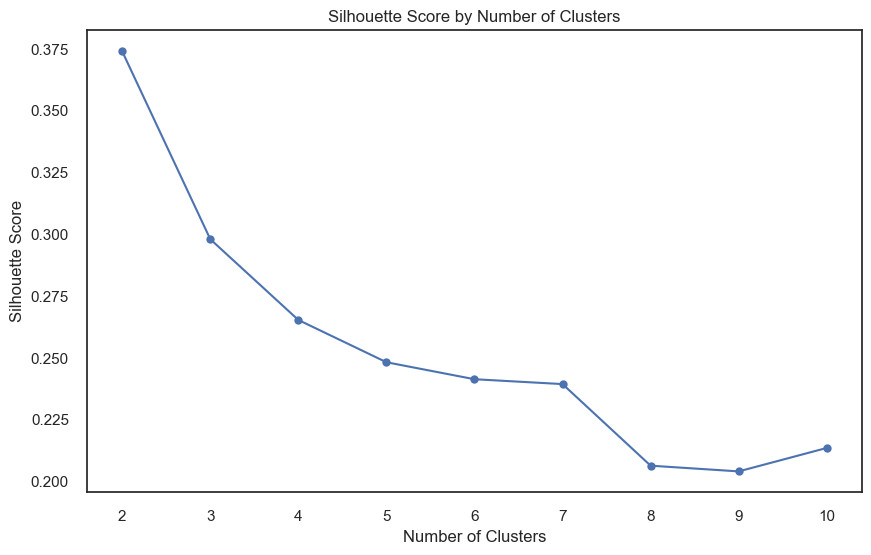

In [124]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.show()

Generally, a higher silhouette score indicates better separation between clusters.



In [125]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

country_data['cluster'] = kmeans.fit_predict(X_scaled)

In [126]:
for cluster in sorted(country_data['cluster'].unique()):

    print(f"\nCluster {cluster}")

    countries = country_data[
        country_data['cluster'] == cluster
    ]['country_name']

    print(countries.tolist())


Cluster 0
['Benin', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic', 'Chad', 'Comoros', 'Congo', 'Côte d’Ivoire', 'Gabon', 'Gambia', 'Ghana', 'Guinea', 'Haiti', 'Iraq', 'Kenya', 'Lao PDR', 'Liberia', 'Madagascar', 'Mali', 'Morocco', 'Mozambique', 'Nepal', 'Niger', 'Nigeria', 'Pakistan', 'Senegal', 'Somalia', 'Swaziland', 'Tajikistan', 'Togo', 'Uganda', 'Venezuela']

Cluster 1
['Australia', 'Austria', 'Belgium', 'Canada', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Hong Kong SAR of China', 'Iceland', 'Ireland', 'Israel', 'Luxembourg', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Singapore', 'Sweden', 'Switzerland', 'United Arab Emirates', 'United Kingdom', 'United States']

Cluster 2
['Afghanistan', 'Bangladesh', 'Botswana', 'Cambodia', 'DR Congo', 'Egypt', 'Eswatini', 'Ethiopia', 'India', 'Iran', 'Jordan', 'Lebanon', 'Lesotho', 'Malawi', 'Mauritania', 'Myanmar', 'Namibia', 'Rwanda', 'Sierra Leone', 'South Sudan', 'Sri Lanka', 'State of Palestine', 'Ta

This gives us a direct interpretation of the model.

#### Visualize the clusters

Because we're working with many dimensions, we need dimensionality reduction for visualization.

A great choice is PCA.

In [127]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

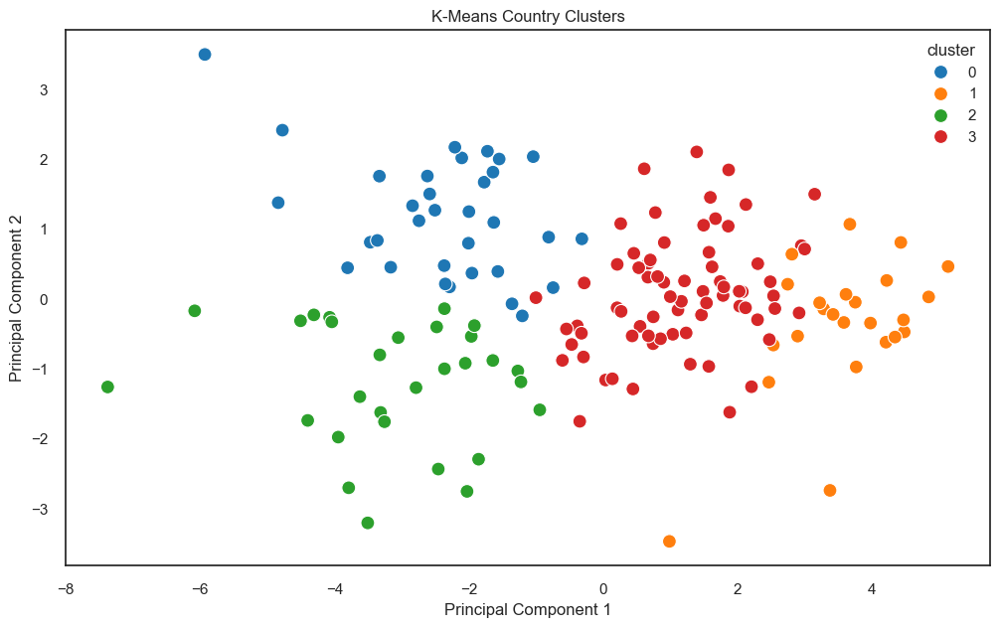

In [128]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['country_name'] = country_data['country_name']
pca_df['cluster'] = country_data['cluster']

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10',
    s=100
)

plt.title('K-Means Country Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

## Multiple Clustering
Elbow Method to determine the number of clusters to be formed Clustering 


In [129]:
# Perform clustering using the K-Means algorithm

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import (
    euclidean_distances,
    manhattan_distances,
    cosine_distances
)



# 1. Apply PCA
pca = PCA(n_components=10, random_state=42)

X_pca = pca.fit_transform(X_scaled)

# 2. Perform K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(X_pca)

# 3. Get cluster centroids and labels
centroids = kmeans.cluster_centers_
labels = kmeans.labels_

# 4. Calculate distances from every observation
#    to every cluster centroid
euclidean_dist = euclidean_distances(
    X_pca,
    centroids
)

manhattan_dist = manhattan_distances(
    X_pca,
    centroids
)

cosine_dist = cosine_distances(
    X_pca,
    centroids
)

### 3D Ploting 

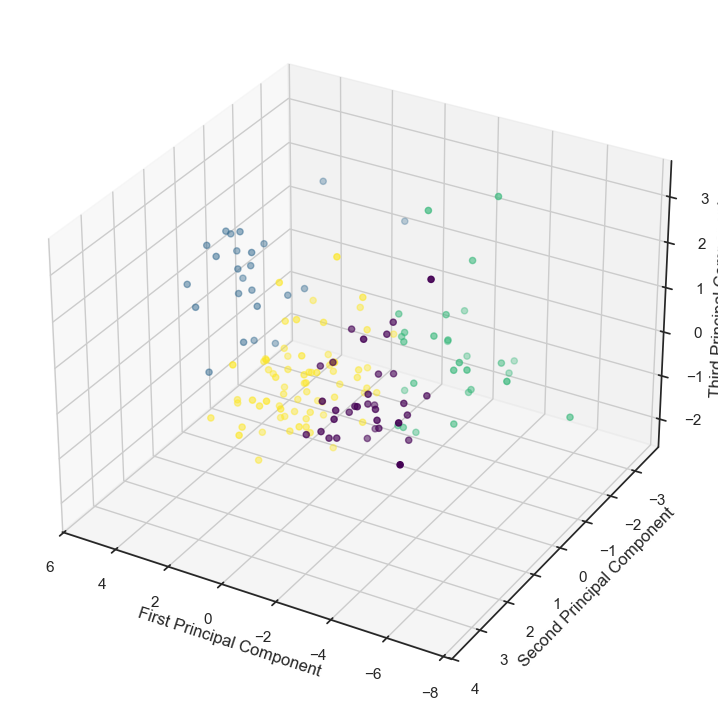

In [130]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=labels, cmap='viridis')
#ax.legend(['Malign'])
ax.set_xlabel('First Principal Component')
ax.set_ylabel('Second Principal Component')
ax.set_zlabel('Third Principal Component')
ax.view_init(30, 120)



## Silhouette Score Calculation

### Introduction
The provided code calculates the silhouette score for K-Means clustering using three different distance metrics: Euclidean, Manhattan, and Cosine.

### Code Explanation
The code snippet performs the following steps:

**Importing Libraries**: The code imports the silhouette_score function from scikit-learn.metrics module. This function is used to compute the silhouette score, which quantifies the quality of clustering.

### Silhouette Score Calculation:

For K-Means clustering with Euclidean distance: The silhouette_avg_euclidean variable is assigned the silhouette score calculated using the 'euclidean' metric.
For K-Means clustering with Manhattan distance: The silhouette_avg_manhattan variable is assigned the silhouette score calculated using the 'manhattan' metric.
For K-Means clustering with Cosine distance: The silhouette_avg_cosine variable is assigned the silhouette score calculated using the 'cosine' metric.
##Results
The silhouette score is a measure of how similar an object is to its own cluster (cohesion) compared to other clusters (separation). It ranges from -1 to 1, where a high value indicates that the object is well matched to its own cluster and poorly matched to neighboring clusters.

* Silhouette Score (Euclidean): silhouette_avg_euclidean
* Silhouette Score (Manhattan): silhouette_avg_manhattan
* Silhouette Score (Cosine): silhouette_avg_cosine

A higher silhouette score suggests better clustering results.

In [131]:
from sklearn.metrics import silhouette_score
import numpy as np

# Calculate silhouette score for K-Means with Euclidean distance
silhouette_avg_euclidean = silhouette_score(X_pca, labels, metric='euclidean')

# Calculate silhouette score for K-Means with Manhattan distance
silhouette_avg_manhattan = silhouette_score(X_pca, labels, metric='manhattan')

# Calculate silhouette score for K-Means with Cosine distance
silhouette_avg_cosine = silhouette_score(X_pca, labels, metric='cosine')

In [132]:
print(f"Silhouette Score (Euclidean): {silhouette_avg_euclidean:.4f}")
print(f"Silhouette Score (Manhattan): {silhouette_avg_manhattan:.4f}")
print(f"Silhouette Score (Cosine): {silhouette_avg_cosine:.4f}")

Silhouette Score (Euclidean): 0.2654
Silhouette Score (Manhattan): 0.2391
Silhouette Score (Cosine): 0.2085


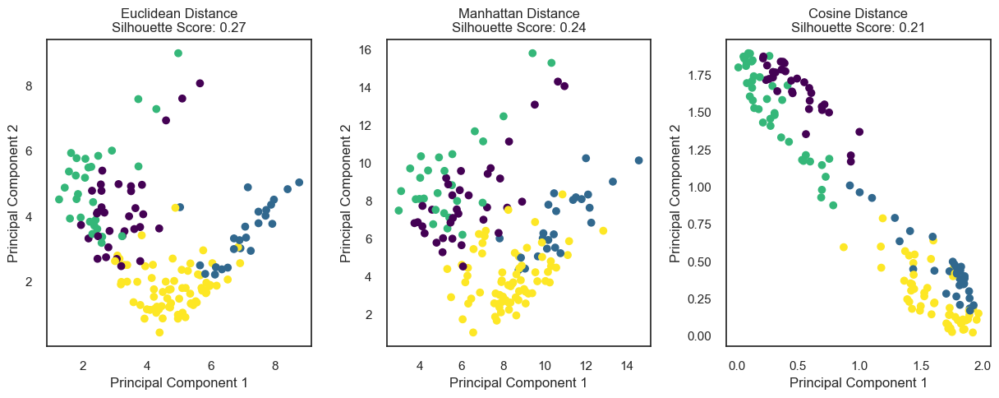

In [133]:
# Visualize the clustering results with silhouette score
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 2)
plt.scatter(euclidean_dist[:, 2], euclidean_dist[:, 3], c=np.argmin(euclidean_dist, axis=1), cmap='viridis')
plt.title('Euclidean Distance\nSilhouette Score: {:.2f}'.format(silhouette_avg_euclidean))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.subplot(1, 4, 3)
plt.scatter(manhattan_dist[:, 2], manhattan_dist[:, 3], c=np.argmin(manhattan_dist, axis=1), cmap='viridis')
plt.title('Manhattan Distance\nSilhouette Score: {:.2f}'.format(silhouette_avg_manhattan))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.subplot(1, 4, 4)
plt.scatter(cosine_dist[:, 2], cosine_dist[:, 3], c=np.argmin(cosine_dist, axis=1), cmap='viridis')
plt.title('Cosine Distance\nSilhouette Score: {:.2f}'.format(silhouette_avg_cosine))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

### The K-means clusters summary

The K-means clusters show a clear well-being gradient across countries.

**Cluster 0**: Represents countries with lower life satisfaction and weaker social and economic foundations, reflecting more limited health and institutional quality.

**Cluster 1**: Represents the strongest-performing countries, with the highest life evaluation, stronger GDP per capita, better social support, healthier life expectancy, greater freedom of choice, and lower perceived corruption.

**Cluster 2**: Captures the lowest-performing countries, characterized by poor life evaluation, weak social support, low economic strength, and greater vulnerability. 
 
 **Cluster 3**: Includes countries with moderate conditions, where economic and social indicators are acceptable but not exceptional.

Overall, the clusters divide countries based on the strength of their social, economic, and institutional conditions, which strongly align with differences in happiness and life evaluation.

## Conclusion

This project provided a comprehensive analysis of the World Happiness dataset through exploratory data analysis and K-Means clustering.

During the exploratory analysis, the dataset was cleaned by standardising column names, checking for missing values, and verifying duplicate records. The analysis showed that life evaluation differs considerably between countries and changes over time. Countries such as Finland, Denmark, Iceland, Norway, and the Netherlands achieved the highest average life-evaluation scores, while countries affected by economic, social, and political challenges generally recorded lower scores.

The relationship between happiness rank and life evaluation was also examined. As expected, countries with better rankings generally had higher life-evaluation scores. The analysis of yearly averages showed that global life evaluation experienced some variation over time, with an overall increase in the later years of the dataset. Country-level trend analysis further demonstrated that countries do not follow identical patterns: some improved, some declined, and others remained relatively stable.

For the machine-learning section, K-Means clustering was applied to country-level averages of ranking, life evaluation, economic conditions, social support, healthy life expectancy, freedom, generosity, corruption perceptions, and the dystopia residual. The numerical features were standardised before clustering so that variables with larger scales did not dominate the distance calculations.

The Elbow Method and Silhouette Score were used to evaluate different numbers of clusters. Although the highest silhouette score among the tested values occurred at a smaller number of clusters, four clusters were selected because they provided a useful and interpretable division of countries. PCA was then used to reduce the multidimensional data to two and three dimensions for visualisation.

The resulting clusters revealed a broad well-being gradient. The strongest-performing cluster contained countries with high life evaluation, better economic conditions, stronger social support, healthier life expectancy, greater freedom, and lower perceived corruption. Other clusters represented countries with moderate or lower levels of well-being, while the lowest-performing cluster generally showed weaker social and economic conditions and lower life-evaluation scores.

The Euclidean, Manhattan, and Cosine distance comparisons produced different silhouette scores. Euclidean distance achieved the highest score among the three metrics used in the final comparison, although the overall separation was moderate rather than perfect. This suggests that the countries share overlapping characteristics and that happiness is influenced by several interconnected factors rather than a single variable.

Overall, the project demonstrates that happiness rankings are closely associated with broader social, economic, health, and institutional conditions. Exploratory data analysis helped identify important patterns, while K-Means clustering grouped countries according to their similarities across multiple indicators. The results should be interpreted as descriptive patterns rather than definitive causal relationships. In addition, cluster labels are arbitrary, and the clustering results may be influenced by the inclusion of rank and life evaluation as features. Nevertheless, the combination of EDA, correlation analysis, trend analysis, PCA, and K-Means clustering provided a useful overall understanding of international differences in well-being.